#### Rating data analysis

count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

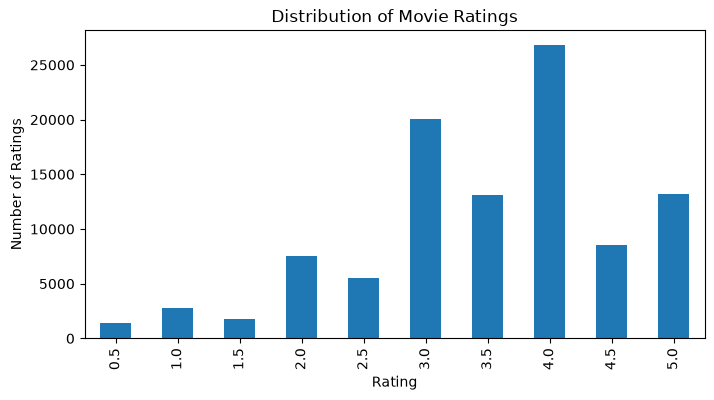

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ratings_df = pd.read_csv("../data/processed/movielens_ratings_cleaned.csv")
movies_df = pd.read_csv("../data/processed/movielens_movies_cleaned.csv")

display(ratings_df["rating"].describe())

ratings_df["rating"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 4),
    title="Distribution of Movie Ratings",
    xlabel="Rating",
    ylabel="Number of Ratings"
)

plt.show()

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64

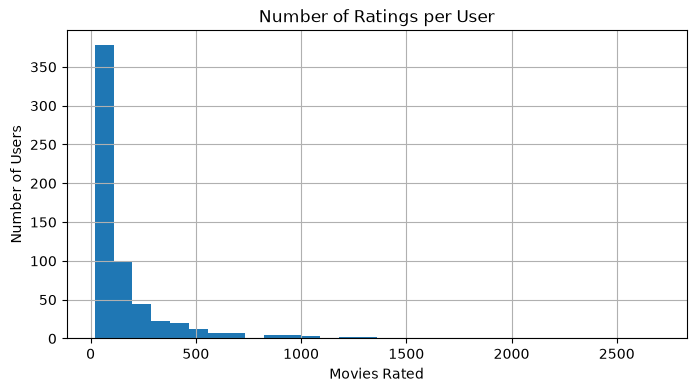

In [2]:
ratings_per_user = ratings_df.groupby("userId").size()

display(ratings_per_user.describe())

ratings_per_user.hist(
    bins=30,
    figsize=(8, 4)
)

plt.title("Number of Ratings per User")
plt.xlabel("Movies Rated")
plt.ylabel("Number of Users")
plt.show()

count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
dtype: float64

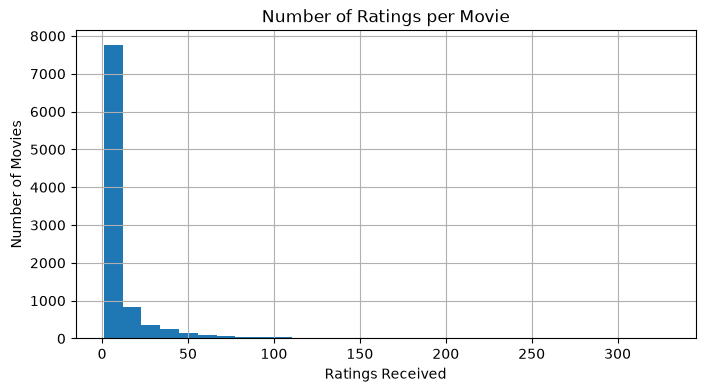

In [3]:
ratings_per_movie = ratings_df.groupby("movieId").size()

display(ratings_per_movie.describe())

ratings_per_movie.hist(
    bins=30,
    figsize=(8, 4)
)

plt.title("Number of Ratings per Movie")
plt.xlabel("Ratings Received")
plt.ylabel("Number of Movies")
plt.show()

In [4]:
n_users = ratings_df["userId"].nunique()
n_movies = ratings_df["movieId"].nunique()

total_possible_ratings = n_users * n_movies
actual_ratings = len(ratings_df)

sparsity = 1 - (actual_ratings / total_possible_ratings)

print(f"Total possible ratings: {total_possible_ratings:,}")
print(f"Actual ratings: {actual_ratings:,}")
print(f"Matrix sparsity: {sparsity:.2%}")

Total possible ratings: 5,931,640
Actual ratings: 100,836
Matrix sparsity: 98.30%
